In [1]:
# 폴더 안의 항목을 나열하는 라이브러리
import os
# .npz 파일을 읽는 라이브러리
import numpy as np

# AMASS 폴더 안의 항목 출력
print(sorted(os.listdir('/home/jaesik/mnt/HumanML3D/amass_data')))
# 그중 KIT 폴더 안의 항목 출력
print(sorted(os.listdir('/home/jaesik/mnt/HumanML3D/amass_data/KIT')))
# 그중 3번 폴더 안의 항목 출력
print(sorted(os.listdir('/home/jaesik/mnt/HumanML3D/amass_data/KIT/3')))

# 파일 하나 열기
amass = np.load('/home/jaesik/mnt/HumanML3D/amass_data/KIT/3/kick_high_left02_poses.npz', allow_pickle=True)
# 파일 안의 키 이름을 하나씩 꺼내기
for key in amass.files:
    # 키 이름과 배열 크기 출력
    print(key, amass[key].shape)

print(amass["poses"])

['ACCAD', 'ACCAD.tar.bz2', 'ACCAD.verified.json', 'BMLhandball', 'BMLhandball.tar.bz2', 'BMLhandball.verified.json', 'BMLmovi', 'BMLmovi.tar.bz2', 'BMLmovi.verified.json', 'BMLrub.tar.bz2', 'BMLrub.verified.json', 'BioMotionLab_NTroje', 'CMU', 'CMU.tar.bz2', 'CMU.verified.json', 'DFaust.tar.bz2', 'DFaust.verified.json', 'DFaust_67', 'EKUT', 'EKUT.tar.bz2', 'EKUT.verified.json', 'EyesJapanDataset.tar.bz2', 'EyesJapanDataset.verified.json', 'Eyes_Japan_Dataset', 'HDM05.tar.bz2', 'HDM05.verified.json', 'HumanEva', 'HumanEva.tar.bz2', 'HumanEva.verified.json', 'KIT', 'KIT.tar.bz2', 'KIT.verified.json', 'LICENSE.txt', 'MPI_HDM05', 'MPI_Limits', 'MPI_mosh', 'MoSh.tar.bz2', 'MoSh.verified.json', 'PosePrior.tar.bz2', 'PosePrior.verified.json', 'SFU', 'SFU.tar.bz2', 'SFU.verified.json', 'SSM.tar.bz2', 'SSM.verified.json', 'SSM_synced', 'TCDHands.tar.bz2', 'TCDHands.verified.json', 'TCD_handMocap', 'TotalCapture', 'TotalCapture.tar.bz2', 'TotalCapture.verified.json', 'Transitions.tar.bz2', 'Tran

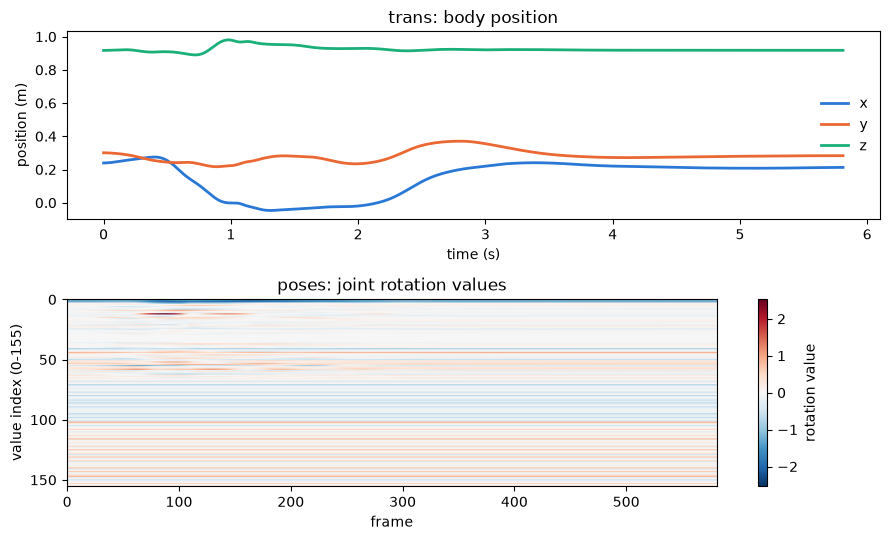

In [2]:
# 그림을 그리는 라이브러리
import matplotlib.pyplot as plt

# 프레임 번호를 초 단위 시간으로 바꾸기
time = np.arange(len(amass['trans']))/amass['mocap_framerate']
# 위아래로 칸 2개 만들기
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5))

# 위 칸에 trans의 x 값을 시간에 따라 그리기
axes[0].plot(time, amass['trans'][:, 0], color='#2a78d6', linewidth=2, label='x')
# 위 칸에 trans의 y 값을 시간에 따라 그리기
axes[0].plot(time, amass['trans'][:, 1], color='#eb6834', linewidth=2, label='y')
# 위 칸에 trans의 z 값을 시간에 따라 그리기
axes[0].plot(time, amass['trans'][:, 2], color='#1baf7a', linewidth=2, label='z')
# 위 칸의 제목 지정
axes[0].set_title('trans: body position')
# 위 칸의 가로축 이름 지정
axes[0].set_xlabel('time (s)')
# 위 칸의 세로축 이름 지정
axes[0].set_ylabel('position (m)')
# 위 칸에 범례 표시
axes[0].legend(frameon=False, loc='center right')

# poses 값의 절댓값 최대를 구해 색 범위로 사용
limit = np.abs(amass['poses']).max()
# 아래 칸에 poses 전체를 프레임(가로) × 값 번호(세로) 이미지로 그리기
image = axes[1].imshow(amass['poses'].T, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
# 아래 칸의 제목 지정
axes[1].set_title('poses: joint rotation values')
# 아래 칸의 가로축 이름 지정
axes[1].set_xlabel('frame')
# 아래 칸의 세로축 이름 지정
axes[1].set_ylabel('value index (0-155)')
# 아래 칸 옆에 색 막대 표시
fig.colorbar(image, ax=axes[1], label='rotation value')

# 칸 간격 자동 조정
plt.tight_layout()
# 그림 출력
plt.show()